# Lib


In [ ]:
import warnings

warnings.filterwarnings("ignore")

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "src" / "evaluation" / "checkpoints.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project containing src/.")
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import os
import copy
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


from scipy.ndimage import binary_erosion, distance_transform_edt

import kagglehub

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


# Model Define


In [ ]:
DEFAULT_EVAL_CONFIG = {
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    "image_height": 256,
    "image_width": 256,
    "num_classes": 3,
    # Architecture and preprocessing are read from each checkpoint.
    # Evaluation data.
    "batch_size": 16,
    # Windows/Jupyter-safe; Linux users may increase this if needed.
    "num_workers": 0,
    "image_col": None,
    "mask_col": None,
    "dataset_handle": "avcuongy/bkai-igh-neopolyp-small-sample",
    # Input preprocessing.
    "normalize_input": True,
    "input_mean": [0.485, 0.456, 0.406],
    "input_std": [0.229, 0.224, 0.225],
    # Checkpoint loading.
    # Mean Teacher: choose "student" or "teacher" (best saved state first).
    "mean_teacher_state": "student",
    "strict_weight_loading": True,
}

BASE_CLASS_NAMES = {
    0: "background",
    1: "non-neoplastic",
    2: "neoplastic",
}

In [5]:
def decode_ground_truth(mask_rgb):
    mask = np.asarray(mask_rgb)

    if mask.ndim == 2:
        unique_values = np.unique(mask)

        if np.isin(unique_values, [0, 1, 2]).all():
            return mask.astype(np.uint8)

        raise ValueError(
            "Grayscale mask must contain only class IDs 0, 1, 2. "
            f"Found: {unique_values[:20]}"
        )

    if mask.ndim != 3 or mask.shape[-1] != 3:
        raise ValueError(f"Expected HxWx3 RGB mask, got shape={mask.shape}")

    colors = np.array(
        [
            [0, 0, 0],
            [0, 255, 0],
            [255, 0, 0],
        ],
        dtype=np.float32,
    )

    distances = np.sum(
        (mask.astype(np.float32)[:, :, None, :] - colors[None, None, :, :]) ** 2,
        axis=-1,
    )

    return np.argmin(distances, axis=-1).astype(np.uint8)


def pick_column(
    dataframe,
    explicit_column=None,
    candidates=None,
    required=True,
):
    if explicit_column is not None:
        if explicit_column not in dataframe.columns:
            raise KeyError(
                f"Column '{explicit_column}' not found. "
                f"Available: {dataframe.columns.tolist()}"
            )
        return explicit_column

    normalized = {str(column).strip().lower(): column for column in dataframe.columns}

    for candidate in candidates or []:
        if candidate.lower() in normalized:
            return normalized[candidate.lower()]

    if len(dataframe.columns) == 1:
        return dataframe.columns[0]

    if required:
        raise KeyError(
            "Cannot infer CSV column automatically. "
            f"Available: {dataframe.columns.tolist()}"
        )

    return None


class SegmentationEvaluationDataset(Dataset):
    IMAGE_COLUMN_CANDIDATES = [
        "image",
        "image_name",
        "image_path",
        "filename",
        "file_name",
        "file",
        "id",
    ]

    MASK_COLUMN_CANDIDATES = [
        "mask",
        "mask_name",
        "mask_path",
        "label",
        "label_path",
        "gt",
        "gt_path",
    ]

    def __init__(
        self,
        dataframe,
        image_dir,
        mask_dir,
        transform=None,
        image_col=None,
        mask_col=None,
    ):
        self.df = dataframe.reset_index(drop=True).copy()
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.transform = transform

        self.image_col = pick_column(
            self.df,
            explicit_column=image_col,
            candidates=self.IMAGE_COLUMN_CANDIDATES,
            required=True,
        )

        self.mask_col = pick_column(
            self.df,
            explicit_column=mask_col,
            candidates=self.MASK_COLUMN_CANDIDATES,
            required=False,
        )

    @staticmethod
    def resolve_path(root_dir, value):
        path = Path(str(value))
        return path if path.is_absolute() else Path(root_dir) / path

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image_path = self.resolve_path(
            self.image_dir,
            row[self.image_col],
        )

        mask_value = (
            row[self.mask_col] if self.mask_col is not None else row[self.image_col]
        )

        mask_path = self.resolve_path(
            self.mask_dir,
            mask_value,
        )

        image_bgr = cv2.imread(
            str(image_path),
            cv2.IMREAD_COLOR,
        )
        mask_raw = cv2.imread(
            str(mask_path),
            cv2.IMREAD_UNCHANGED,
        )

        if image_bgr is None:
            raise FileNotFoundError(f"Cannot read image: {image_path}")

        if mask_raw is None:
            raise FileNotFoundError(f"Cannot read mask: {mask_path}")

        image = cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB,
        )

        if mask_raw.ndim == 3:
            mask_raw = cv2.cvtColor(
                mask_raw,
                cv2.COLOR_BGR2RGB,
            )

        mask = decode_ground_truth(mask_raw)

        if self.transform is not None:
            transformed = self.transform(
                image=image,
                mask=mask,
            )
            image = transformed["image"]
            mask = transformed["mask"]

        if not torch.is_tensor(mask):
            mask = torch.from_numpy(mask)

        return {
            "image": image,
            "mask": mask.long(),
            "image_path": str(image_path),
            "mask_path": str(mask_path),
            "image_name": image_path.name,
        }


def build_eval_transform(config):
    transform_steps = [
        A.Resize(
            height=int(config["image_height"]),
            width=int(config["image_width"]),
        )
    ]

    if config["normalize_input"]:
        transform_steps.append(
            A.Normalize(
                mean=tuple(config["input_mean"]),
                std=tuple(config["input_std"]),
            )
        )

    transform_steps.append(ToTensorV2())

    return A.Compose(transform_steps)


def build_test_data(config):
    device = torch.device(config["device"])
    eval_transform = build_eval_transform(config)

    dataset_root = Path(kagglehub.dataset_download(config["dataset_handle"]))

    data_dir = dataset_root / "data"
    test_csv_path = data_dir / "sample" / "test.csv"

    if not test_csv_path.exists():
        raise FileNotFoundError(f"Test CSV not found: {test_csv_path}")

    test_df = pd.read_csv(test_csv_path)

    test_dataset = SegmentationEvaluationDataset(
        dataframe=test_df,
        image_dir=data_dir,
        mask_dir=data_dir,
        transform=eval_transform,
        image_col=config["image_col"],
        mask_col=config["mask_col"],
    )

    requested_num_workers = int(config.get("num_workers", 0))

    if requested_num_workers < 0:
        raise ValueError("CONFIG['num_workers'] must be >= 0.")

    effective_num_workers = requested_num_workers

    # Windows starts DataLoader workers with spawn. Dataset classes defined
    # inside a Jupyter notebook are not reliably importable in those workers,
    # which can surface only as "DataLoader worker exited unexpectedly".
    if os.name == "nt" and requested_num_workers > 0:
        print(
            "[DataLoader] Windows notebook detected: "
            f"num_workers={requested_num_workers} -> 0."
        )
        effective_num_workers = 0

    test_loader = DataLoader(
        test_dataset,
        batch_size=int(config["batch_size"]),
        shuffle=False,
        num_workers=effective_num_workers,
        pin_memory=device.type == "cuda",
    )

    return test_df, test_dataset, test_loader

In [ ]:
# Architectures are imported by the shared loader for each checkpoint.

In [ ]:
from evaluation.checkpoints import (
    build_and_load_model,
    checkpoint_entries as _checkpoint_entries,
    load_checkpoint_file,
)

MODEL_TYPES = ("unet", "mean_teacher_unet")


def checkpoint_entries(groups):
    invalid = set(groups) - set(MODEL_TYPES)
    if invalid:
        raise ValueError(
            f"This notebook only supports {MODEL_TYPES}; got {sorted(invalid)}."
        )
    return _checkpoint_entries(groups)

In [ ]:
def extract_logits(
    model_output,
    model_label,
):
    if torch.is_tensor(model_output):
        logits = model_output

    elif isinstance(model_output, (tuple, list)):
        tensors = [item for item in model_output if torch.is_tensor(item)]
        logits = next(
            (item for item in tensors if item.ndim == 4),
            None,
        )

    elif isinstance(model_output, dict):
        logits = None

        for key in (
            "logits",
            "out",
            "prediction",
            "pred",
        ):
            value = model_output.get(key)

            if torch.is_tensor(value):
                logits = value
                break

    elif hasattr(model_output, "logits") and torch.is_tensor(model_output.logits):
        logits = model_output.logits

    else:
        logits = None

    if logits is None:
        raise TypeError(f"{model_label}: cannot extract logits " "from model output.")

    if logits.ndim != 4:
        raise ValueError(
            f"{model_label}: expected logits "
            f"[B, C, H, W], got {tuple(logits.shape)}."
        )

    return logits


@torch.inference_mode()
def predict_batch(
    model,
    images,
    model_label,
    num_classes,
    output_size=None,
):
    logits = extract_logits(
        model(images),
        model_label,
    )

    if logits.shape[1] != num_classes:
        raise ValueError(
            f"{model_label}: expected "
            f"{num_classes} output channels, "
            f"got {logits.shape[1]}."
        )

    if output_size is not None and logits.shape[-2:] != tuple(output_size):
        logits = F.interpolate(
            logits,
            size=tuple(output_size),
            mode="bilinear",
            align_corners=False,
        )

    return torch.argmax(
        logits,
        dim=1,
    )


def hd95_binary(pred_mask, true_mask):
    """
    Directional-max symmetric HD95 for one binary mask pair.

    The 95th percentile is computed separately in both directions and the
    larger value is returned, matching the non-directed MONAI/DeepMind style.

    Empty-mask convention:
        - both prediction and ground truth empty -> NaN (excluded from mean)
        - exactly one side empty                 -> image-diagonal penalty
    """
    pred = np.asarray(pred_mask, dtype=bool)
    true = np.asarray(true_mask, dtype=bool)

    pred_empty = not pred.any()
    true_empty = not true.any()

    if pred_empty and true_empty:
        return np.nan

    if pred_empty or true_empty:
        height, width = true.shape[-2:]
        return float(np.hypot(height, width))

    pred_surface = pred ^ binary_erosion(pred)
    true_surface = true ^ binary_erosion(true)

    if not pred_surface.any():
        pred_surface = pred
    if not true_surface.any():
        true_surface = true

    distance_to_true = distance_transform_edt(~true_surface)
    distance_to_pred = distance_transform_edt(~pred_surface)

    distances_pred_to_true = distance_to_true[pred_surface]
    distances_true_to_pred = distance_to_pred[true_surface]

    directed_hd95_pred_to_true = np.percentile(
        distances_pred_to_true,
        95,
    )
    directed_hd95_true_to_pred = np.percentile(
        distances_true_to_pred,
        95,
    )

    return float(
        max(
            directed_hd95_pred_to_true,
            directed_hd95_true_to_pred,
        )
    )


def safe_divide(
    numerator,
    denominator,
):
    if denominator == 0:
        return np.nan

    return float(numerator / denominator)


@torch.inference_mode()
def evaluate_model(
    model,
    model_label,
    loader,
    device,
    num_classes,
    class_names,
):
    confusion = np.zeros(
        (num_classes, num_classes),
        dtype=np.int64,
    )

    hd95_values = {class_id: [] for class_id in range(num_classes)}

    model = model.to(device)
    model.eval()

    for batch in loader:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )
        targets = (
            batch["mask"]
            .to(
                device,
                non_blocking=True,
            )
            .long()
        )

        predictions = predict_batch(
            model=model,
            images=images,
            model_label=model_label,
            num_classes=num_classes,
            output_size=targets.shape[-2:],
        )

        targets_np = targets.cpu().numpy()
        predictions_np = predictions.cpu().numpy()

        encoded = num_classes * targets_np.reshape(-1) + predictions_np.reshape(-1)

        confusion += np.bincount(
            encoded,
            minlength=num_classes**2,
        ).reshape(
            num_classes,
            num_classes,
        )

        for sample_index in range(targets_np.shape[0]):
            for class_id in range(num_classes):
                hd95_values[class_id].append(
                    hd95_binary(
                        predictions_np[sample_index] == class_id,
                        targets_np[sample_index] == class_id,
                    )
                )

    rows = []

    for class_id in range(num_classes):
        true_positive = int(
            confusion[
                class_id,
                class_id,
            ]
        )

        false_positive = int(confusion[:, class_id].sum() - true_positive)

        false_negative = int(confusion[class_id, :].sum() - true_positive)

        gt_pixels = int(confusion[class_id, :].sum())

        pred_pixels = int(
            confusion[
                :,
                class_id,
            ].sum()
        )

        hd_values = np.asarray(
            hd95_values[class_id],
            dtype=np.float64,
        )
        valid_hd_values = hd_values[~np.isnan(hd_values)]

        rows.append(
            {
                "model": model_label,
                "class_id": class_id,
                "class_name": class_names[class_id],
                "dice": safe_divide(
                    2 * true_positive,
                    (2 * true_positive + false_positive + false_negative),
                ),
                "iou": safe_divide(
                    true_positive,
                    (true_positive + false_positive + false_negative),
                ),
                "hd95": (
                    float(valid_hd_values.mean())
                    if valid_hd_values.size > 0
                    else np.nan
                ),
                "precision": safe_divide(
                    true_positive,
                    (true_positive + false_positive),
                ),
                "recall": safe_divide(
                    true_positive,
                    (true_positive + false_negative),
                ),
                "gt_pixels": gt_pixels,
                "pred_pixels": pred_pixels,
            }
        )

    class_results = pd.DataFrame(rows)

    foreground = class_results[class_results["class_id"] > 0]

    metric_columns = [
        "dice",
        "iou",
        "hd95",
        "precision",
        "recall",
    ]

    def macro_row(
        class_id,
        class_name,
        frame,
    ):
        row = {
            "model": model_label,
            "class_id": class_id,
            "class_name": class_name,
            "gt_pixels": int(frame["gt_pixels"].sum()),
            "pred_pixels": int(frame["pred_pixels"].sum()),
        }

        row.update(
            {column: frame[column].mean(skipna=True) for column in metric_columns}
        )

        return row

    results = pd.concat(
        [
            class_results,
            pd.DataFrame(
                [
                    macro_row(
                        "macro_fg",
                        "macro_foreground_only",
                        foreground,
                    ),
                    macro_row(
                        "macro_all",
                        "macro_all_classes",
                        class_results,
                    ),
                ]
            ),
        ],
        ignore_index=True,
    )

    model.to("cpu")

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return results, confusion


def evaluate_checkpoints(models, loaders, configs, device, class_names):
    evaluation_tables = {}
    confusion_matrices = {}
    for label, model in models.items():
        print(f"Evaluating: {label}")
        results, confusion = evaluate_model(
            model=model,
            model_label=label,
            loader=loaders[label],
            device=device,
            num_classes=int(configs[label]["num_classes"]),
            class_names=class_names,
        )
        evaluation_tables[label] = results
        confusion_matrices[label] = confusion
    evaluation_df = pd.concat(evaluation_tables.values(), ignore_index=True)
    comparison_df = evaluation_df[evaluation_df["class_id"].eq("macro_fg")].reset_index(
        drop=True
    )
    return evaluation_df, comparison_df, confusion_matrices

# Main


In [9]:
CONFIG = copy.deepcopy(DEFAULT_EVAL_CONFIG)
CONFIG["mean_teacher_state"] = "teacher"  # Change to "student" to evaluate Student.
device = torch.device(CONFIG["device"])
class_names = dict(BASE_CLASS_NAMES)
print("Device:", device)

Device: cpu


In [10]:
CHECKPOINTS = {
    "unet": {
        "half": PROJECT_ROOT / "models/baseline/best_UNet_half.pth",
        "quarter": PROJECT_ROOT / "models/baseline/best_UNet_quarter.pth",
    },
    "mean_teacher_unet": {
        "half": PROJECT_ROOT / "models/mean teacher/best_mean_teacher_unet_half.pth",
    },
}

# Plot loss


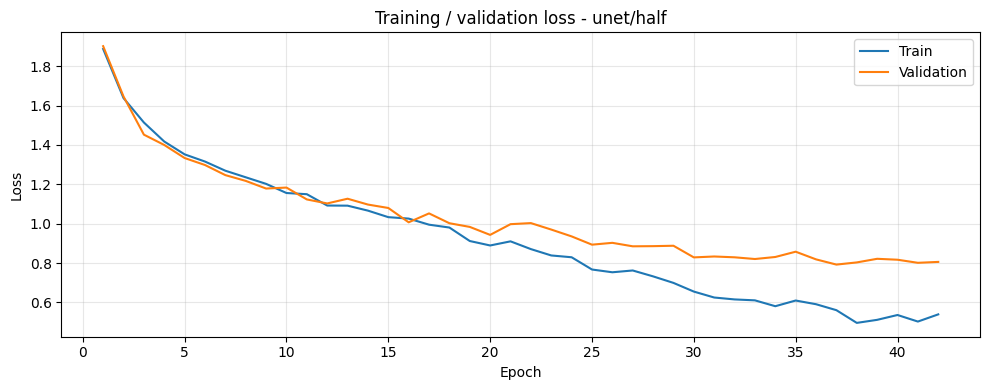

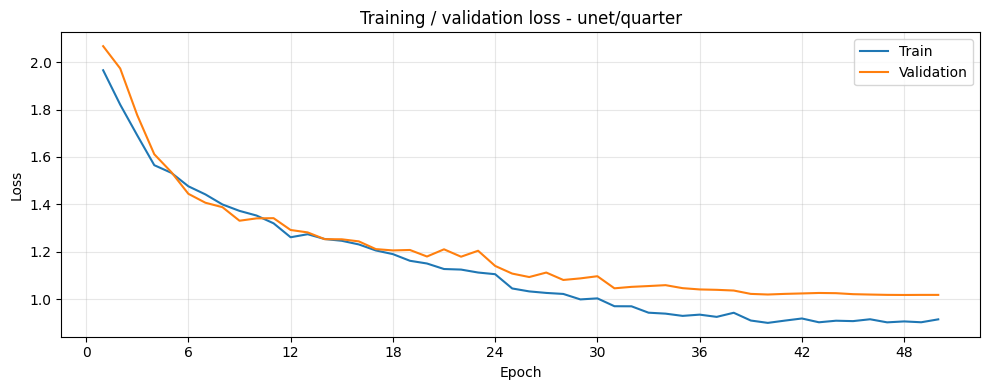

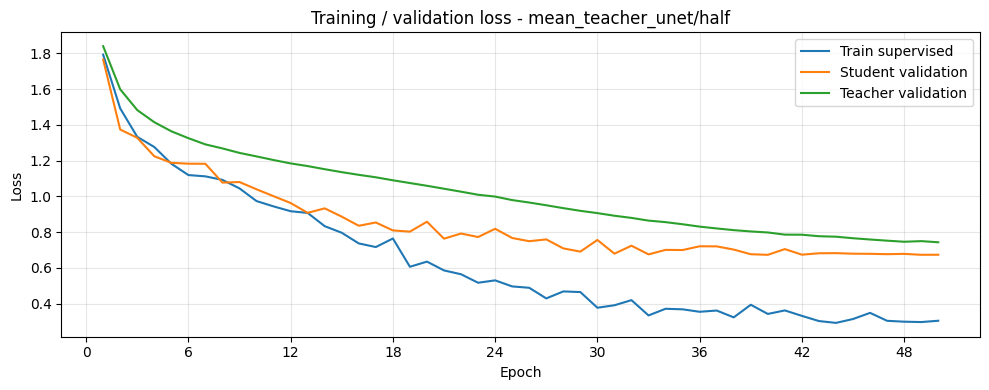

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_checkpoint_losses(checkpoints):
    entries = list(checkpoint_entries(checkpoints))
    if not entries:
        print("No checkpoint paths configured for loss plots.")
        return
    methods = list(checkpoints)
    runs = ["half", "quarter"]
    panels = {}
    for label, model_type, path in entries:
        run = label.split("/", 1)[1] if "/" in label else "default"
        if run not in runs:
            runs.append(run)
        panels[model_type, run] = path
    fig, axes = plt.subplots(
        len(methods),
        len(runs),
        figsize=(8 * len(runs), 4 * len(methods)),
        squeeze=False,
    )
    for row, model_type in enumerate(methods):
        method_name = (
            "Mean Teacher" if model_type.startswith("mean_teacher_") else "Supervised"
        )
        for col, run in enumerate(runs):
            ax = axes[row, col]
            ax.set(title=f"{method_name} - {run}", xlabel="Epoch", ylabel="Loss")
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
            ax.grid(True, alpha=0.3)
            path = panels.get((model_type, run))
            if path is None:
                ax.text(
                    0.5,
                    0.5,
                    "No checkpoint configured",
                    ha="center",
                    va="center",
                    transform=ax.transAxes,
                )
                continue
            checkpoint = load_checkpoint_file(path)
            history = checkpoint.get("history", {})
            del checkpoint
            if not isinstance(history, dict):
                history = {}
            if "supervised_loss" in history:
                curves = {
                    "supervised_loss": "Train supervised",
                    "student_val_loss": "Student validation",
                    "teacher_val_loss": "Teacher validation",
                }
            else:
                curves = {"train_loss": "Train", "val_loss": "Validation"}
            for key, title in curves.items():
                values = np.asarray(history.get(key, []), dtype=float)
                if values.ndim == 1 and values.size:
                    ax.plot(np.arange(1, len(values) + 1), values, label=title)
            if ax.lines:
                ax.legend()
            else:
                ax.text(
                    0.5,
                    0.5,
                    "No saved loss history",
                    ha="center",
                    va="center",
                    transform=ax.transAxes,
                )
    fig.suptitle("Loss Plot", fontsize=14)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


plot_checkpoint_losses(CHECKPOINTS)

In [12]:
MODELS = {}
MODEL_CONFIGS = {}
MODEL_INFO = {}
TEST_DATASETS = {}
TEST_LOADERS = {}

entries = list(checkpoint_entries(CHECKPOINTS))
if not entries:
    raise ValueError("Add at least one checkpoint path to CHECKPOINTS.")

for label, model_type, path in entries:
    model, model_config, info = build_and_load_model(path, model_type, CONFIG)
    _, dataset, loader = build_test_data(model_config)
    MODELS[label] = model
    MODEL_CONFIGS[label] = model_config
    MODEL_INFO[label] = info
    TEST_DATASETS[label] = dataset
    TEST_LOADERS[label] = loader
    print(
        f"{label}: {len(dataset)} test images, "
        f"input={model_config['image_height']}x{model_config['image_width']}"
    )

[unet] b:\_projects\poply-image-segmentation\models\baseline\best_UNet_half.pth | weights=model_state_dict | strict load OK
unet/half: 200 test images, input=256x256
[unet] b:\_projects\poply-image-segmentation\models\baseline\best_UNet_quarter.pth | weights=model_state_dict | strict load OK
unet/quarter: 200 test images, input=256x256
[mean_teacher_unet] b:\_projects\poply-image-segmentation\models\mean teacher\best_mean_teacher_unet_half.pth | weights=teacher_state_dict | strict load OK
mean_teacher_unet/half: 200 test images, input=256x256


,model_type,weights,best_epoch,checkpoint_path
unet/half,unet,model_state_dict,32,b:\_projects\poply-image-segmentation\models\b...
unet/quarter,unet,model_state_dict,49,b:\_projects\poply-image-segmentation\models\b...
mean_teacher_unet/half,mean_teacher_unet,teacher_state_dict,48,b:\_projects\poply-image-segmentation\models\m...


In [13]:
evaluation_df, model_comparison_df, confusion_matrices = evaluate_checkpoints(
    models=MODELS,
    loaders=TEST_LOADERS,
    configs=MODEL_CONFIGS,
    device=device,
    class_names=class_names,
)

Evaluating: unet/half
Evaluating: unet/quarter
Evaluating: mean_teacher_unet/half


# Table


In [14]:
evaluation_df.round(4)

,model,class_id,class_name,dice,iou,hd95,precision,recall,gt_pixels,pred_pixels
0,unet/half,0,background,0.9947,0.9894,8.8089,0.9939,0.9955,12364023,12383801
1,unet/half,1,non-neoplastic,0.5805,0.4089,205.1502,0.5147,0.6656,74485,96331
2,unet/half,2,neoplastic,0.8949,0.8098,74.3999,0.9246,0.8671,668692,627068
3,unet/half,macro_fg,macro_foreground_only,0.7377,0.6094,139.7751,0.7196,0.7663,743177,723399
4,unet/half,macro_all,macro_all_classes,0.8234,0.7361,96.1197,0.8111,0.8427,13107200,13107200
5,unet/quarter,0,background,0.9929,0.9860,14.3160,0.9932,0.9927,12364023,12357918
6,unet/quarter,1,non-neoplastic,0.4813,0.3169,227.1548,0.3934,0.6196,74485,117298
7,unet/quarter,2,neoplastic,0.8766,0.7804,93.1429,0.9021,0.8526,668692,631984
8,unet/quarter,macro_fg,macro_foreground_only,0.6789,0.5486,160.1488,0.6478,0.7361,743177,749282
9,unet/quarter,macro_all,macro_all_classes,0.7836,0.6944,111.5379,0.7629,0.8216,13107200,13107200


In [15]:
evaluation_df[evaluation_df["class_id"].eq("macro_all")].round(4)

,model,class_id,class_name,dice,iou,hd95,precision,recall,gt_pixels,pred_pixels
4,unet/half,macro_all,macro_all_classes,0.8234,0.7361,96.1197,0.8111,0.8427,13107200,13107200
9,unet/quarter,macro_all,macro_all_classes,0.7836,0.6944,111.5379,0.7629,0.8216,13107200,13107200
14,mean_teacher_unet/half,macro_all,macro_all_classes,0.8075,0.7199,95.9824,0.7705,0.8662,13107200,13107200


In [16]:
model_comparison_df.round(4)

,model,class_id,class_name,dice,iou,hd95,precision,recall,gt_pixels,pred_pixels
0,unet/half,macro_fg,macro_foreground_only,0.7377,0.6094,139.7751,0.7196,0.7663,743177,723399
1,unet/quarter,macro_fg,macro_foreground_only,0.6789,0.5486,160.1488,0.6478,0.7361,743177,749282
2,mean_teacher_unet/half,macro_fg,macro_foreground_only,0.7141,0.5856,138.3956,0.6573,0.8035,743177,805468


# Inference


In [17]:
VIS_CLASS_COLORS = {
    0: (0, 0, 0),
    1: (0, 255, 0),
    2: (255, 0, 0),
}


def class_mask_to_rgb(class_mask, class_colors=VIS_CLASS_COLORS):
    """Convert class-index mask -> RGB mask."""
    class_mask = np.asarray(class_mask)

    rgb = np.zeros(
        (*class_mask.shape, 3),
        dtype=np.uint8,
    )

    for class_id, color in class_colors.items():
        rgb[class_mask == class_id] = color

    return rgb


def _read_rgb_image(image_path):
    image_path = Path(image_path)

    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path}")

    image_bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR,
    )

    if image_bgr is None:
        raise FileNotFoundError(f"Cannot read image: {image_path}")

    return cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB,
    )


def _read_gt_class_mask(ground_truth_path):
    ground_truth_path = Path(ground_truth_path)

    if not ground_truth_path.exists():
        raise FileNotFoundError(f"Ground truth not found: {ground_truth_path}")

    gt_raw = cv2.imread(
        str(ground_truth_path),
        cv2.IMREAD_UNCHANGED,
    )

    if gt_raw is None:
        raise FileNotFoundError(f"Cannot read ground truth: {ground_truth_path}")

    if gt_raw.ndim == 3:
        gt_raw = cv2.cvtColor(
            gt_raw,
            cv2.COLOR_BGR2RGB,
        )

    return decode_ground_truth(gt_raw)


@torch.inference_mode()
def inference_image(
    model,
    model_label,
    image_path,
    transform,
    device,
    num_classes,
    restore_original_size=True,
):
    """
    Inference one image with the same segmentation prediction path used by evaluation.

    Returns:
        pred_mask: HxW class-index mask.
    """
    model = model.to(device)
    model.eval()

    image_rgb = _read_rgb_image(image_path)
    original_height, original_width = image_rgb.shape[:2]

    transformed = transform(image=image_rgb)
    image_tensor = (
        transformed["image"]
        .unsqueeze(0)
        .to(
            device,
            non_blocking=True,
        )
    )

    pred_mask = (
        predict_batch(
            model=model,
            images=image_tensor,
            model_label=model_label,
            num_classes=int(num_classes),
            output_size=None,
        )[0]
        .cpu()
        .numpy()
        .astype(np.uint8)
    )

    if restore_original_size:
        pred_mask = cv2.resize(
            pred_mask,
            (original_width, original_height),
            interpolation=cv2.INTER_NEAREST,
        )

    return pred_mask


def visualize_inference_samples(
    model,
    model_label,
    dataset,
    device,
    num_classes,
    n_sample=4,
    alpha=0.40,
    seed=None,
):
    """
    Random n_sample from test dataset.

    Each image is displayed on ONE ROW:
        Original | Ground Truth | Prediction | Overlay
    """
    if n_sample <= 0:
        raise ValueError("n_sample must be greater than 0.")

    if len(dataset) == 0:
        raise ValueError("Dataset is empty.")

    if dataset.transform is None:
        raise ValueError("Dataset transform is required for inference.")

    n_sample = min(int(n_sample), len(dataset))

    if seed is None:
        sample_indices = np.random.choice(
            len(dataset),
            size=n_sample,
            replace=False,
        )
    else:
        rng = np.random.default_rng(int(seed))
        sample_indices = rng.choice(
            len(dataset),
            size=n_sample,
            replace=False,
        )

    fig, axes = plt.subplots(
        n_sample,
        4,
        figsize=(20, 5 * n_sample),
    )

    if n_sample == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, index in enumerate(sample_indices):
        sample = dataset[int(index)]
        image_path = Path(sample["image_path"])
        gt_path = Path(sample["mask_path"])

        pred_mask = inference_image(
            model=model,
            model_label=model_label,
            image_path=image_path,
            transform=dataset.transform,
            device=device,
            num_classes=num_classes,
            restore_original_size=True,
        )

        image_rgb = _read_rgb_image(image_path)
        gt_class = _read_gt_class_mask(gt_path)

        gt_rgb = class_mask_to_rgb(gt_class)
        pred_rgb = class_mask_to_rgb(pred_mask)

        if gt_rgb.shape[:2] != image_rgb.shape[:2]:
            gt_rgb = cv2.resize(
                gt_rgb,
                (image_rgb.shape[1], image_rgb.shape[0]),
                interpolation=cv2.INTER_NEAREST,
            )

        if pred_rgb.shape[:2] != image_rgb.shape[:2]:
            pred_rgb = cv2.resize(
                pred_rgb,
                (image_rgb.shape[1], image_rgb.shape[0]),
                interpolation=cv2.INTER_NEAREST,
            )

        overlay = cv2.addWeighted(
            image_rgb,
            1.0 - float(alpha),
            pred_rgb,
            float(alpha),
            0,
        )

        panels = [
            (image_rgb, f"Original\n{image_path.name}"),
            (gt_rgb, "Ground Truth"),
            (pred_rgb, "Prediction"),
            (overlay, "Overlay"),
        ]

        for col, (panel, title) in enumerate(panels):
            axes[row, col].imshow(panel)
            axes[row, col].set_title(title)
            axes[row, col].axis("off")

    fig.suptitle(
        f"Random test inference - {model_label}",
        fontsize=14,
        y=1.002,
    )
    plt.tight_layout(pad=0.5)
    plt.show()


def visualize_inference_path(
    model,
    model_label,
    image_path,
    transform,
    device,
    num_classes,
    ground_truth_path=None,
    alpha=0.40,
):
    """
    Inference and visualize one explicitly specified image path.

    With ground_truth_path:
        Original | Ground Truth | Prediction | Overlay

    Without ground_truth_path:
        Original | Prediction | Overlay
    """
    image_path = Path(image_path)

    pred_mask = inference_image(
        model=model,
        model_label=model_label,
        image_path=image_path,
        transform=transform,
        device=device,
        num_classes=num_classes,
        restore_original_size=True,
    )

    image_rgb = _read_rgb_image(image_path)
    pred_rgb = class_mask_to_rgb(pred_mask)

    if pred_rgb.shape[:2] != image_rgb.shape[:2]:
        pred_rgb = cv2.resize(
            pred_rgb,
            (image_rgb.shape[1], image_rgb.shape[0]),
            interpolation=cv2.INTER_NEAREST,
        )

    overlay = cv2.addWeighted(
        image_rgb,
        1.0 - float(alpha),
        pred_rgb,
        float(alpha),
        0,
    )

    if ground_truth_path is None:
        _, axes = plt.subplots(
            1,
            3,
            figsize=(16, 5),
        )

        panels = [
            (image_rgb, f"Original\n{image_path.name}"),
            (pred_rgb, "Prediction"),
            (overlay, "Overlay"),
        ]
    else:
        gt_class = _read_gt_class_mask(ground_truth_path)
        gt_rgb = class_mask_to_rgb(gt_class)

        if gt_rgb.shape[:2] != image_rgb.shape[:2]:
            gt_rgb = cv2.resize(
                gt_rgb,
                (image_rgb.shape[1], image_rgb.shape[0]),
                interpolation=cv2.INTER_NEAREST,
            )

        _, axes = plt.subplots(
            1,
            4,
            figsize=(20, 5),
        )

        panels = [
            (image_rgb, f"Original\n{image_path.name}"),
            (gt_rgb, "Ground Truth"),
            (pred_rgb, "Prediction"),
            (overlay, "Overlay"),
        ]

    for axis, (panel, title) in zip(axes, panels):
        axis.imshow(panel)
        axis.set_title(title)
        axis.axis("off")

    plt.tight_layout()
    plt.show()

    return pred_mask

## Random `n_sample` from test dataset


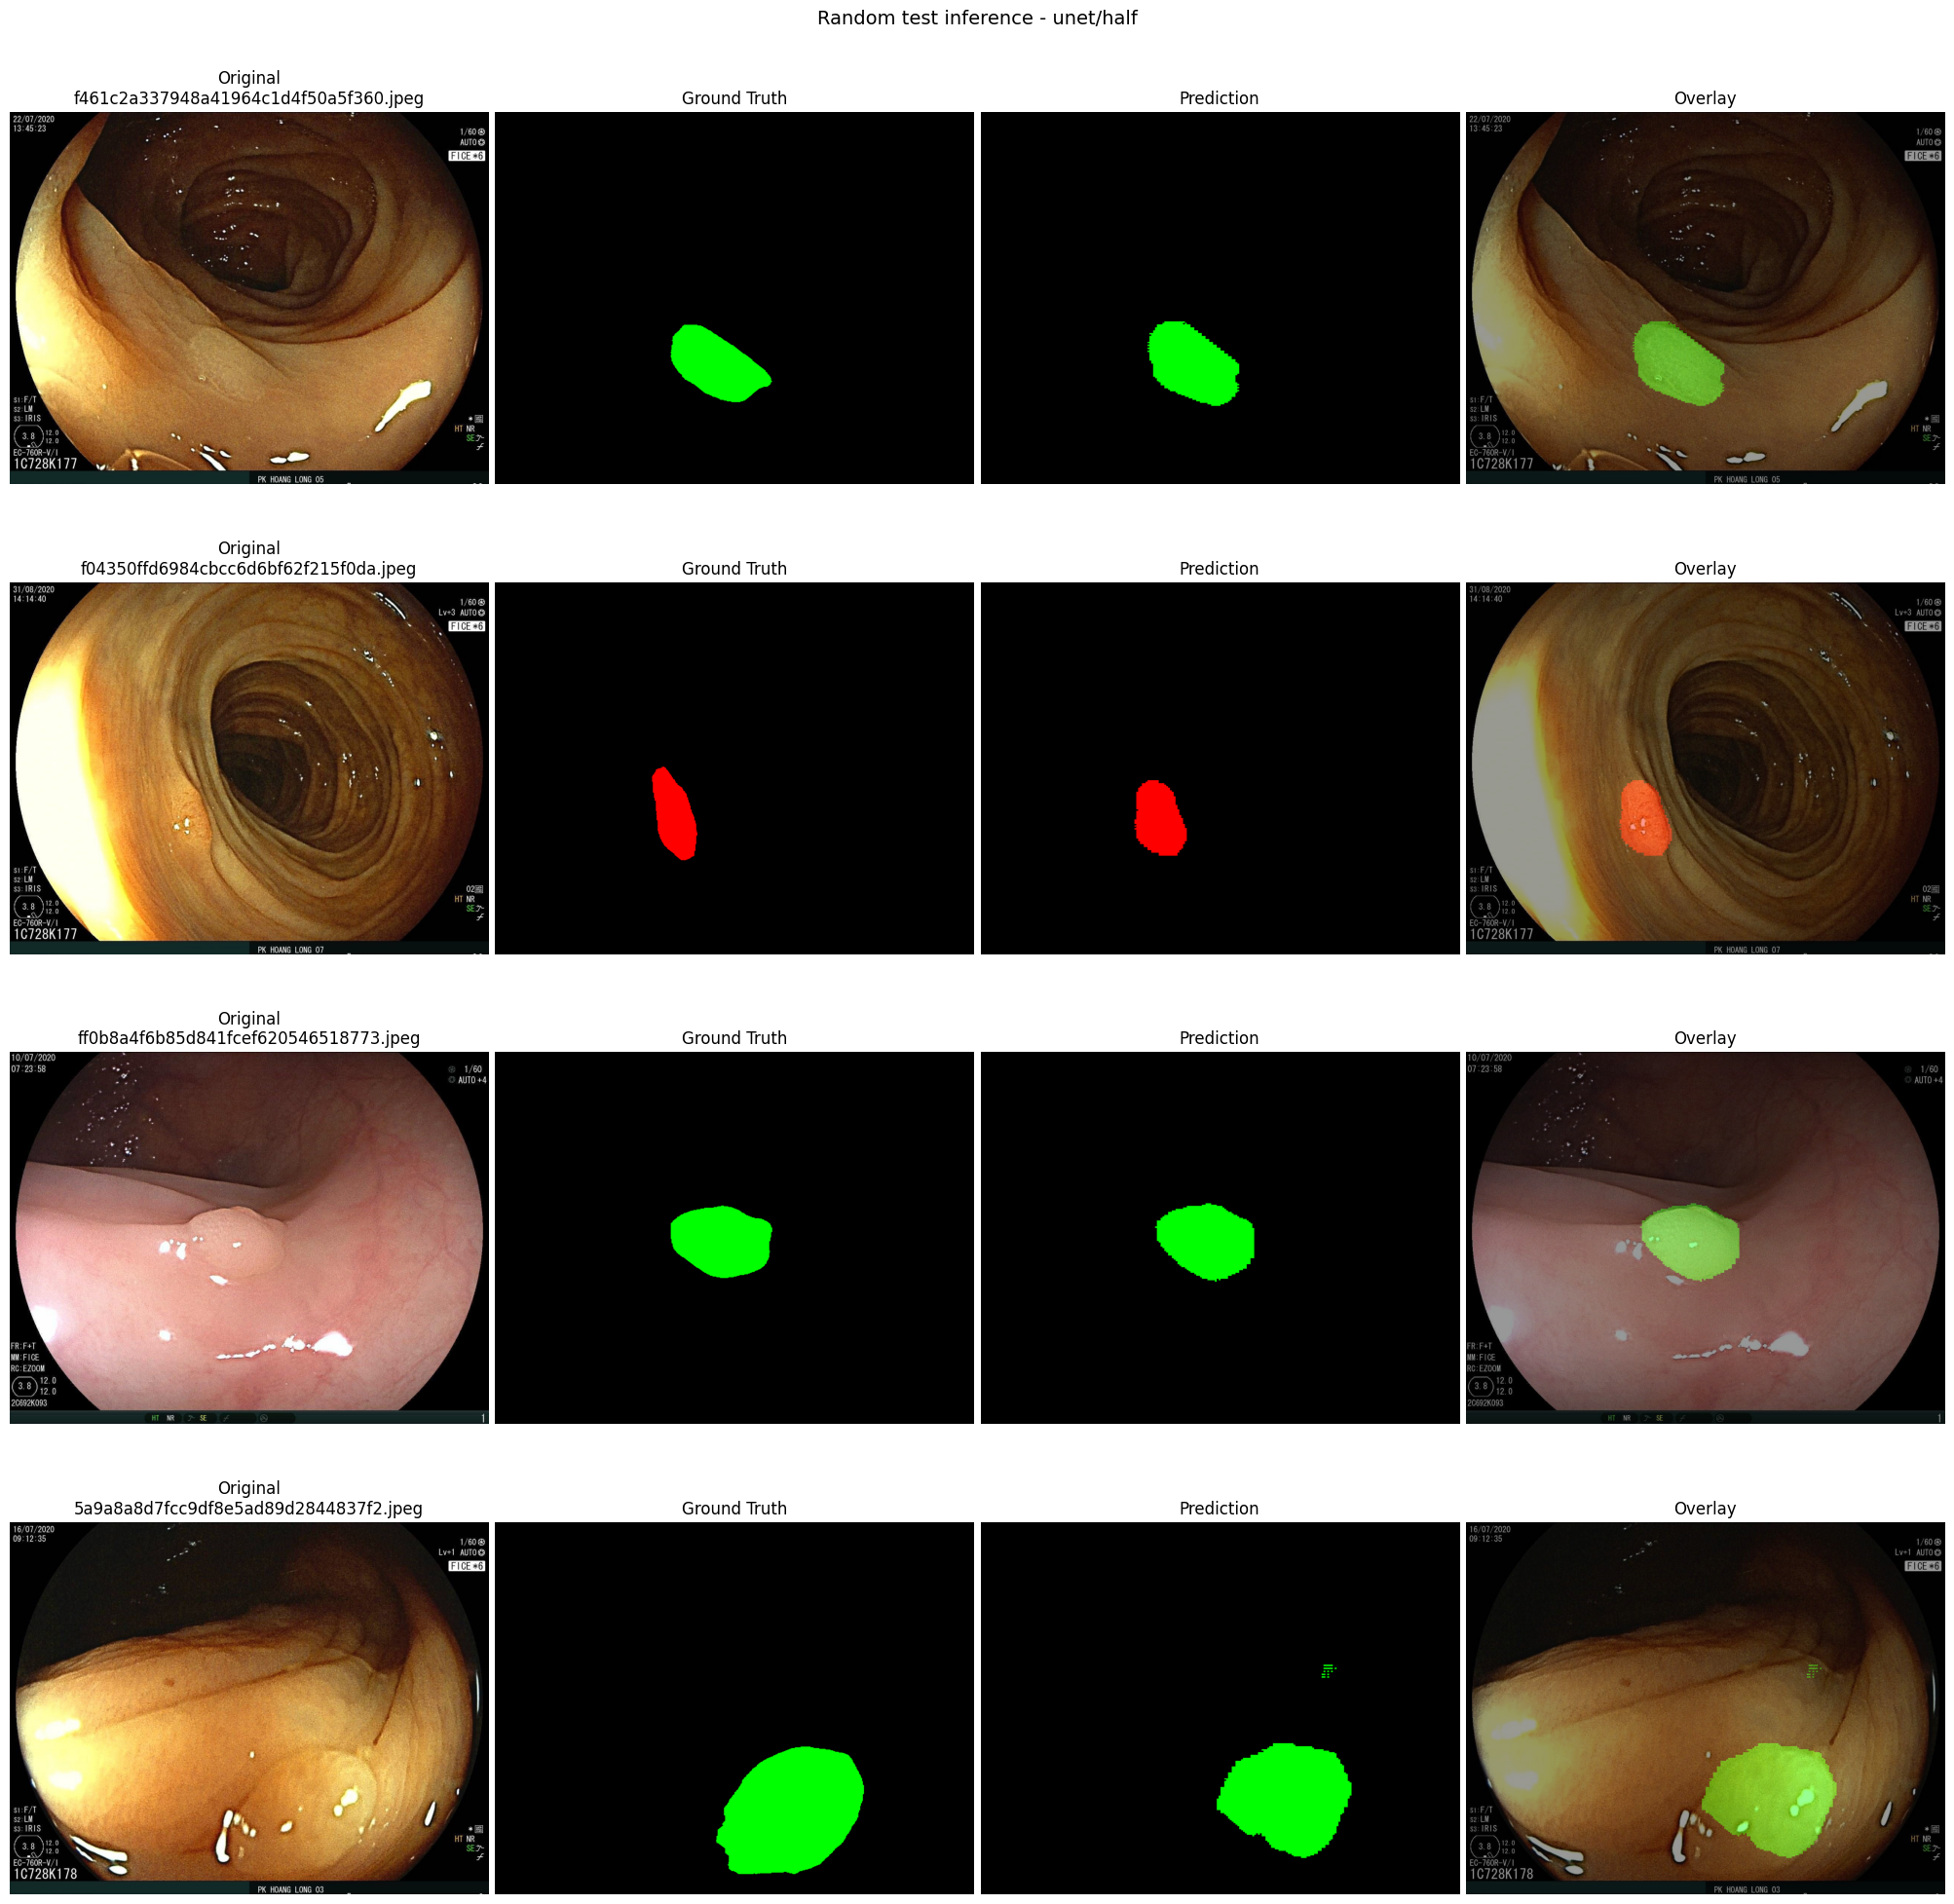

In [23]:
VIS_MODEL_LABEL = next(iter(MODELS))
VIS_MODEL = MODELS[VIS_MODEL_LABEL]
VIS_CONFIG = MODEL_CONFIGS[VIS_MODEL_LABEL]
test_dataset = TEST_DATASETS[VIS_MODEL_LABEL]

N_SAMPLE = 4
VIS_SEED = None

visualize_inference_samples(
    model=VIS_MODEL,
    model_label=VIS_MODEL_LABEL,
    dataset=test_dataset,
    device=device,
    num_classes=int(VIS_CONFIG["num_classes"]),
    n_sample=N_SAMPLE,
    alpha=0.40,
    seed=VIS_SEED,
)

## Inference by specified image path


In [19]:
# Set a specific image path here.
IMAGE_PATH = None
GROUND_TRUTH_PATH = None  # optional

if IMAGE_PATH is None:
    print(
        "Set IMAGE_PATH to run path-based inference. "
        "Set GROUND_TRUTH_PATH too if you want the GT panel."
    )
else:
    visualize_inference_path(
        model=VIS_MODEL,
        model_label=VIS_MODEL_LABEL,
        image_path=IMAGE_PATH,
        transform=test_dataset.transform,
        device=device,
        num_classes=int(VIS_CONFIG["num_classes"]),
        ground_truth_path=GROUND_TRUTH_PATH,
        alpha=0.40,
    )

Set IMAGE_PATH to run path-based inference. Set GROUND_TRUTH_PATH too if you want the GT panel.
